<a href="https://colab.research.google.com/github/BenjaminOrtizO/Estudio/blob/main/EjercicioPPTPronostico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Clonar el repositorio completo
!git clone https://github.com/BenjaminOrtizO/Estudio.git

# Entrar a la carpeta Calidad
%cd /content/Estudio/Pronostico

!git pull

Cloning into 'Estudio'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 53 (delta 12), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 1011.06 KiB | 12.64 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/Estudio/Pronostico
Already up to date.


In [8]:
!ls -l

total 160
-rw-r--r-- 1 root root  5593 Oct 15 03:39 itata_calendario.csv
-rw-r--r-- 1 root root 53831 Oct 15 03:39 itata_componentes_verdad.csv
-rw-r--r-- 1 root root 83101 Oct 15 03:39 itata_demanda.csv
-rw-r--r-- 1 root root   220 Oct 15 03:39 itata_jerarquia.csv
-rw-r--r-- 1 root root   439 Oct 15 03:39 itata_maestro_sku.csv
-rw-r--r-- 1 root root     1 Oct 15 03:39 README.md


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#EJERCICIO 1 CARGAR INSPECCIONAR y PARTICIONAR EN EL TIEMPO


In [10]:
demanda = pd.read_csv('itata_demanda.csv')

demanda.head()

,t,semana,iso_anio,iso_semana,sku,familia,formato_g,canal,pedidos_cajas,despachos_cajas,precio_clp_caja,promo,fiestas_patrias,semana_santa,planta_cerrada
0,1,2023-03-06,2023,10,DUR-480,DUR,480,Retail,1456.0,1456.0,21500.0,0,0,0,0
1,2,2023-03-13,2023,11,DUR-480,DUR,480,Retail,1126.0,1126.0,21514.0,0,0,0,0
2,3,2023-03-20,2023,12,DUR-480,DUR,480,Retail,1234.0,1234.0,21528.0,0,0,0,0
3,4,2023-03-27,2023,13,DUR-480,DUR,480,Retail,1452.0,1452.0,21543.0,0,0,0,0
4,5,2023-04-03,2023,14,DUR-480,DUR,480,Retail,1209.0,1209.0,21557.0,0,0,1,0


In [11]:
demanda['semana'] = pd.to_datetime(demanda['semana'])
demanda.head()

demanda['familia'].unique()

x = (demanda[(demanda['familia'] == 'DUR') &(demanda['canal'] == 'Retail')].groupby('semana')['pedidos_cajas'].sum().sort_index())


x = x.asfreq('W-MON')
x.head()

corte = '2024-12-31'


In [12]:
train = x.loc[:corte]
test = x.loc[pd.Timestamp(corte) + pd.offsets.Week(weekday=0):]

In [13]:
print(train.shape, test.shape, x.isna().mean())

(96,) (86,) 0.0


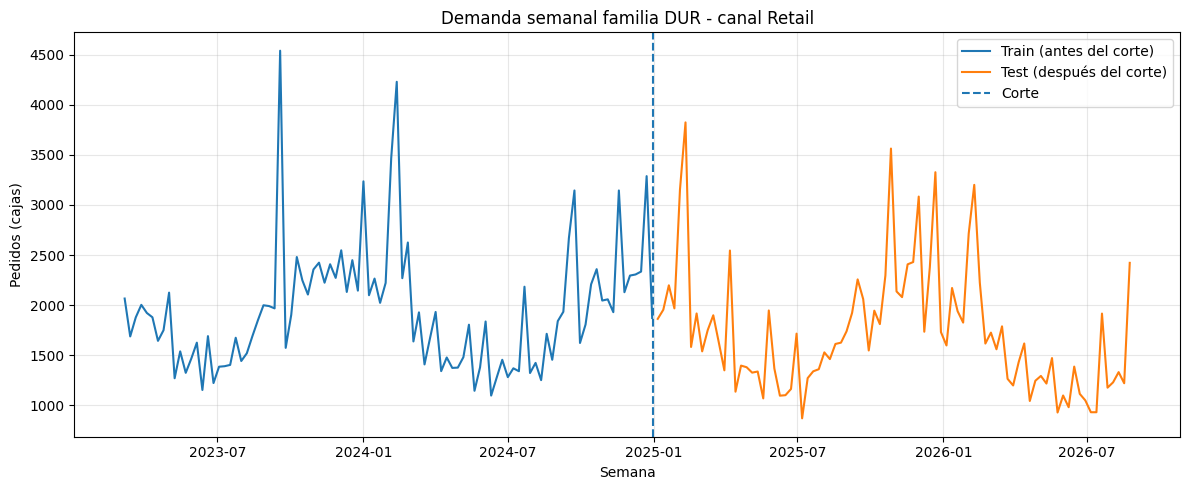

In [14]:


plt.figure(figsize=(12, 5))

plt.plot(train.index, train.values, label='Train (antes del corte)')
plt.plot(test.index, test.values, label='Test (después del corte)')

plt.axvline(pd.Timestamp(corte), linestyle='--', label='Corte')

plt.title('Demanda semanal familia DUR - canal Retail')
plt.xlabel('Semana')
plt.ylabel('Pedidos (cajas)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#EJERCICIO 2

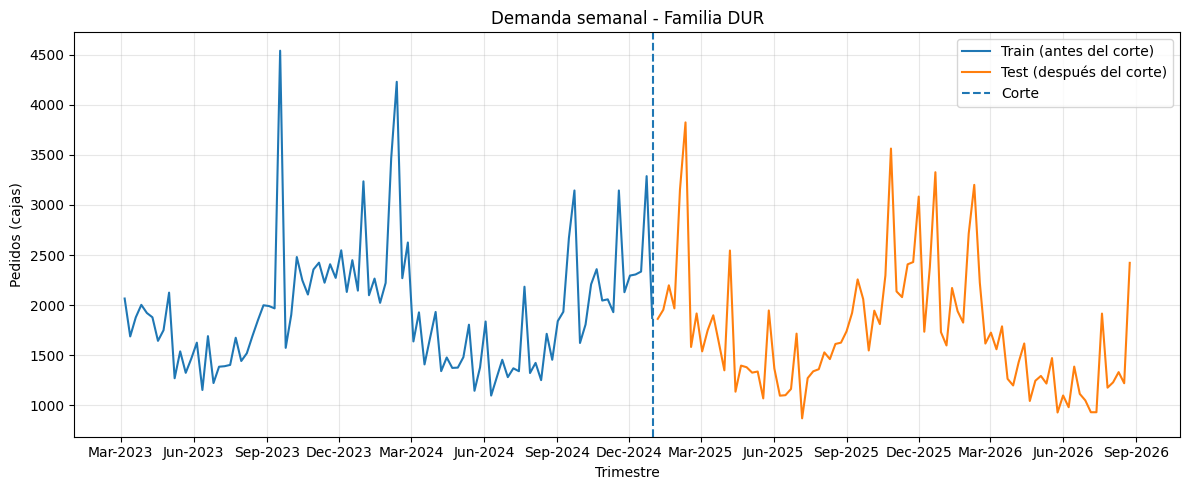

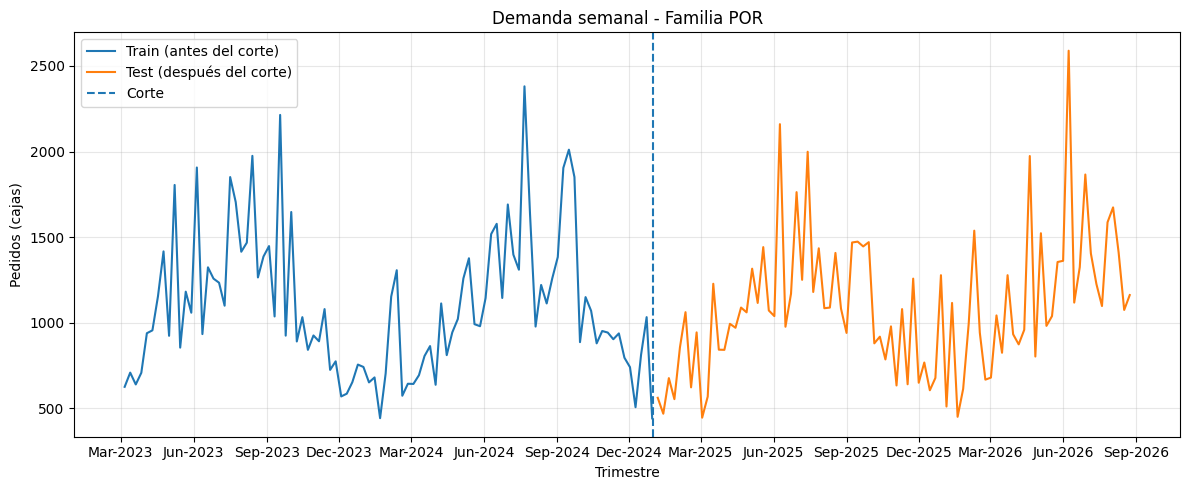

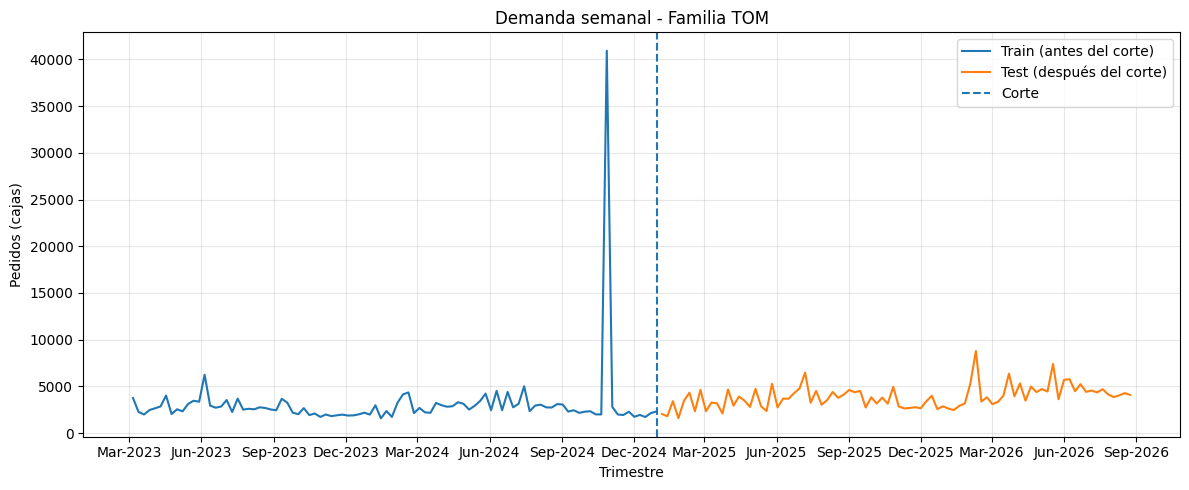

In [15]:
ventas = pd.read_csv('itata_demanda.csv')

# Convertir 'semana' a datetime inmediatamente
ventas['semana'] = pd.to_datetime(ventas['semana'])

corte = pd.to_datetime(corte)

df = (
    ventas.groupby(['familia','semana'])['pedidos_cajas']
    .sum()
    .reset_index()
    .rename(columns={'familia':'unique_id','semana':'ds','pedidos_cajas':'y'})
)

# Ahora sí puedes particionar porque 'ds' ya es datetime
df_train = df[df['ds'] <= corte]
df_test  = df[df['ds'] > corte]





# Generar ticks en marzo, junio, septiembre y diciembre de cada año
ticks = (
    df['ds']
    .dt.to_period('M')
    .drop_duplicates()
    .dt.start_time
)
ticks = ticks[ticks.dt.month.isin([3, 6, 9, 12])]

# 👉 Agregar una etiqueta extra al final (3 meses después del último tick)
ultimo_tick = ticks.max()
extra_tick = ultimo_tick + pd.DateOffset(months=3)

# Convertir a DatetimeIndex y concatenar
ticks = pd.DatetimeIndex(ticks).append(pd.DatetimeIndex([extra_tick]))

# Graficar cada familia
for familia in df['unique_id'].unique():

    train = df_train[df_train['unique_id'] == familia].sort_values('ds')
    test  = df_test[df_test['unique_id'] == familia].sort_values('ds')

    plt.figure(figsize=(12, 5))

    plt.plot(train['ds'], train['y'], label='Train (antes del corte)')
    plt.plot(test['ds'], test['y'], label='Test (después del corte)')

    plt.axvline(corte, color='tab:blue', linestyle='--', label='Corte')

    plt.title(f'Demanda semanal - Familia {familia}')
    plt.xlabel('Trimestre')
    plt.ylabel('Pedidos (cajas)')
    plt.legend()
    plt.grid(alpha=0.3)

    # 👉 Etiquetas en Mar, Jun, Sep, Dic + una extra
    ax = plt.gca()
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks.strftime('%b-%Y'))

    plt.tight_layout()
    plt.show()


In [16]:
!pip install statsforecast

In [17]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive
sf=StatsForecast(
models=[SeasonalNaive(season_length=12), #benchmarkobligatorio
AutoETS(season_length=12)], #ETSelegidoporAICc
freq='W')
sf.fit(df_train)
fc=sf.predict(h=6,level=[80, 95]) #punto+intervalos80/95%




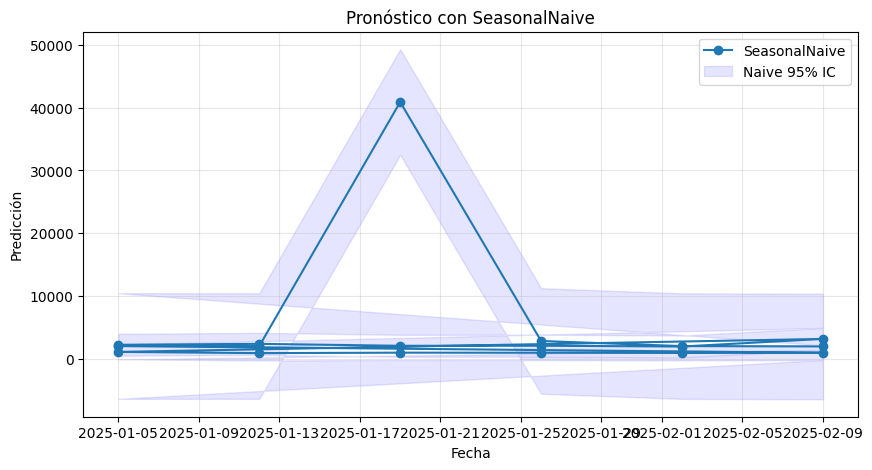

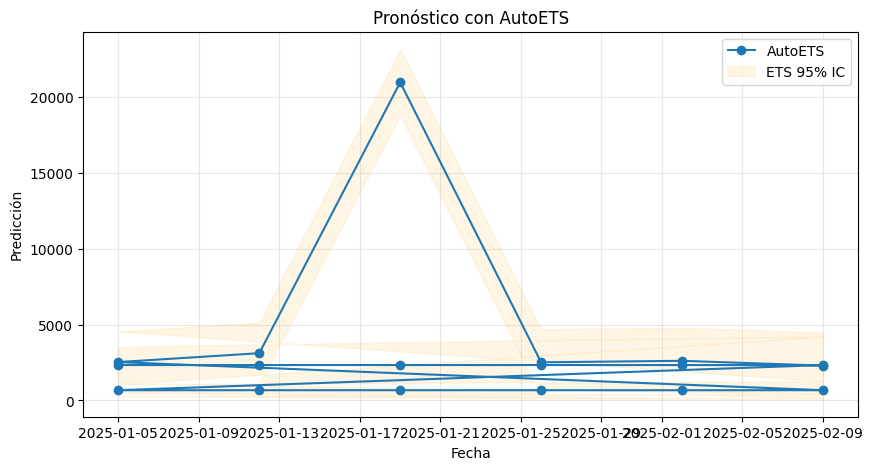

In [18]:
# Pronósticos Naive
plt.figure(figsize=(10,5))
plt.plot(fc['ds'], fc['SeasonalNaive'], label='SeasonalNaive', marker='o')
plt.fill_between(fc['ds'], fc['SeasonalNaive-lo-95'], fc['SeasonalNaive-hi-95'],
                 color='blue', alpha=0.1, label='Naive 95% IC')
plt.title("Pronóstico con SeasonalNaive")
plt.xlabel("Fecha")
plt.ylabel("Predicción")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Pronósticos AutoETS
plt.figure(figsize=(10,5))
plt.plot(fc['ds'], fc['AutoETS'], label='AutoETS', marker='o')
plt.fill_between(fc['ds'], fc['AutoETS-lo-95'], fc['AutoETS-hi-95'],
                 color='orange', alpha=0.1, label='ETS 95% IC')
plt.title("Pronóstico con AutoETS")
plt.xlabel("Fecha")
plt.ylabel("Predicción")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

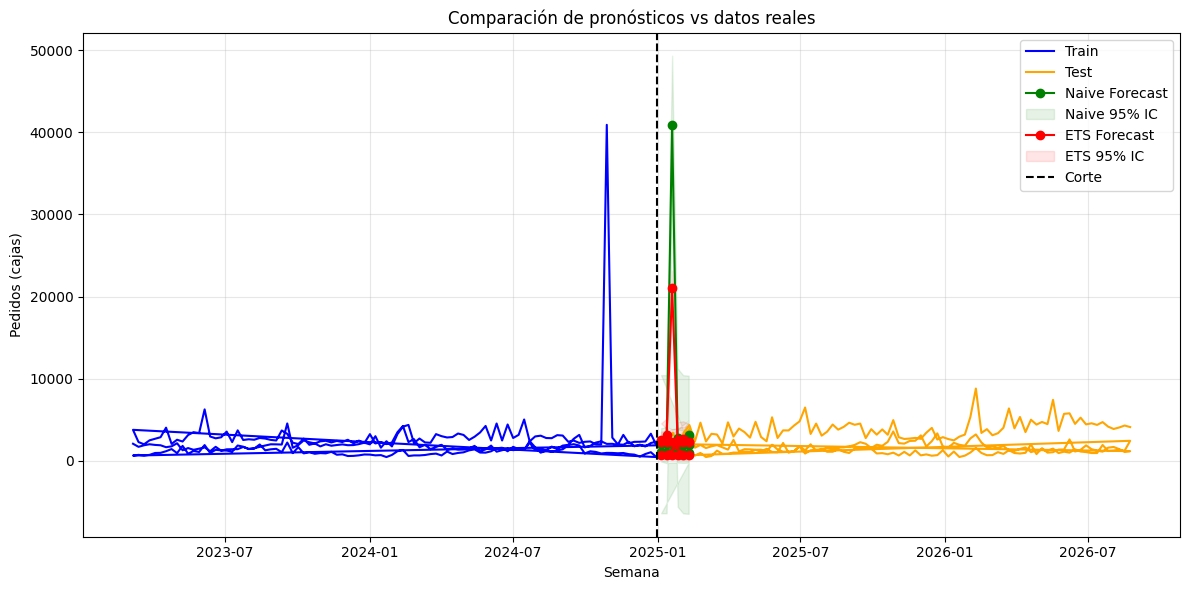

In [26]:
plt.figure(figsize=(12,6))

# Datos históricos
plt.plot(df_train['ds'], df_train['y'], label='Train', color='blue')
plt.plot(df_test['ds'], df_test['y'], label='Test', color='orange')

# Pronóstico Naive
plt.plot(fc['ds'], fc['SeasonalNaive'], label='Naive Forecast', color='green', marker='o')
plt.fill_between(fc['ds'], fc['SeasonalNaive-lo-95'], fc['SeasonalNaive-hi-95'],
                 color='green', alpha=0.1, label='Naive 95% IC')

# Pronóstico AutoETS
plt.plot(fc['ds'], fc['AutoETS'], label='ETS Forecast', color='red', marker='o')
plt.fill_between(fc['ds'], fc['AutoETS-lo-95'], fc['AutoETS-hi-95'],
                 color='red', alpha=0.1, label='ETS 95% IC')

# Corte temporal
plt.axvline(corte, color='black', linestyle='--', label='Corte')

plt.title("Comparación de pronósticos vs datos reales")
plt.xlabel("Semana")
plt.ylabel("Pedidos (cajas)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


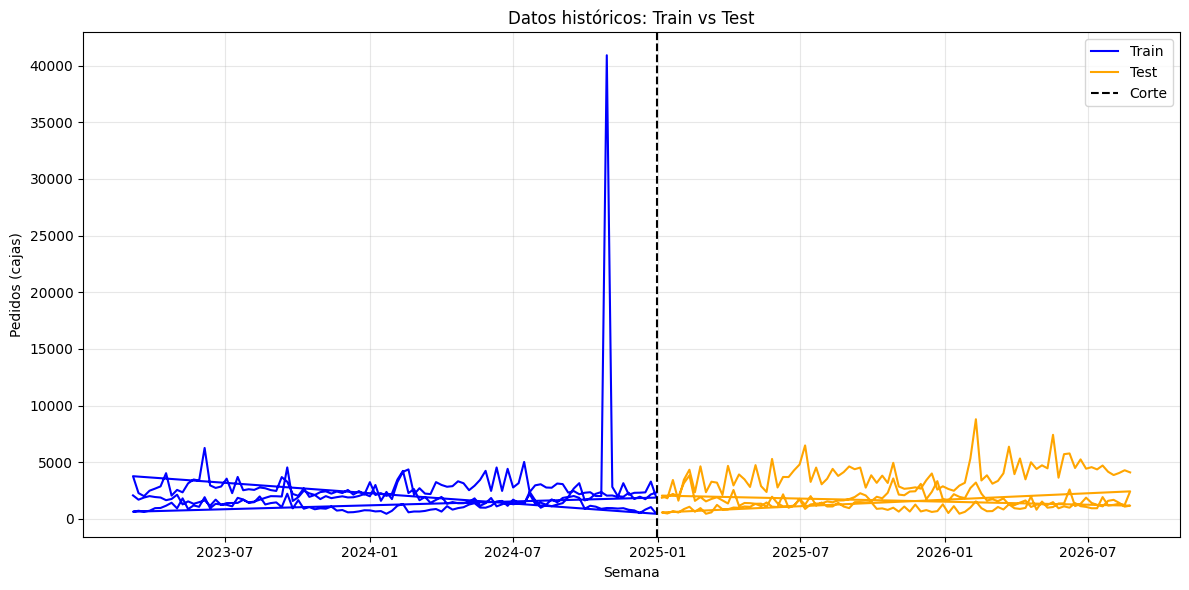

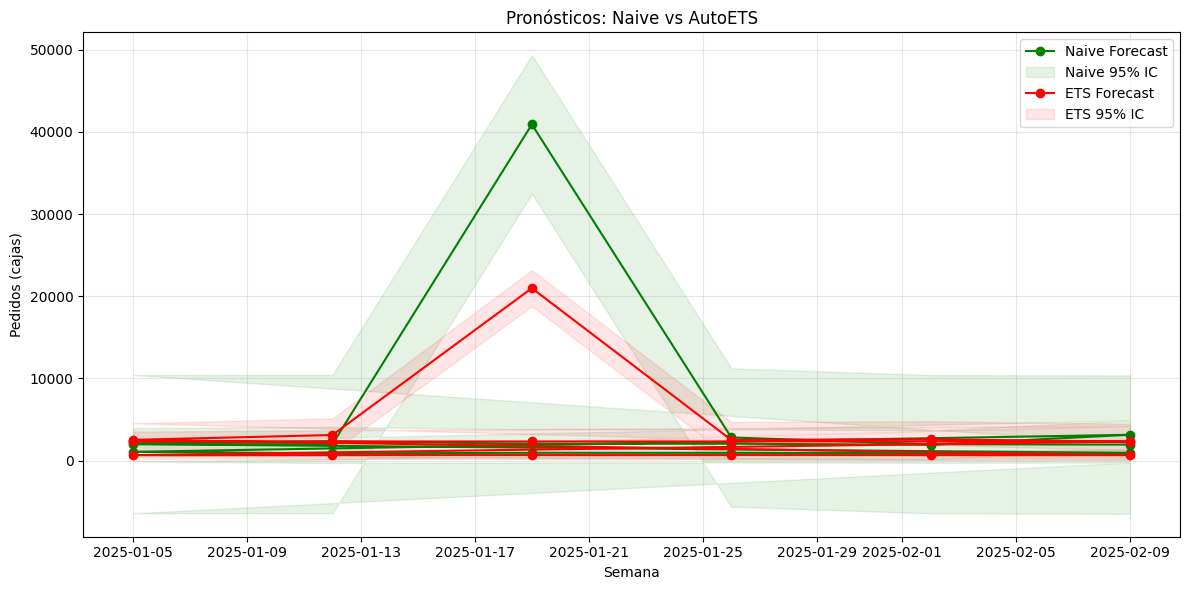

In [27]:
# Gráfico 1: Datos históricos (Train/Test)
plt.figure(figsize=(12,6))
plt.plot(df_train['ds'], df_train['y'], label='Train', color='blue')
plt.plot(df_test['ds'], df_test['y'], label='Test', color='orange')
plt.axvline(corte, color='black', linestyle='--', label='Corte')
plt.title("Datos históricos: Train vs Test")
plt.xlabel("Semana")
plt.ylabel("Pedidos (cajas)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfico 2: Pronósticos (Naive y ETS)
plt.figure(figsize=(12,6))
plt.plot(fc['ds'], fc['SeasonalNaive'], label='Naive Forecast', color='green', marker='o')
plt.fill_between(fc['ds'], fc['SeasonalNaive-lo-95'], fc['SeasonalNaive-hi-95'],
                 color='green', alpha=0.1, label='Naive 95% IC')

plt.plot(fc['ds'], fc['AutoETS'], label='ETS Forecast', color='red', marker='o')
plt.fill_between(fc['ds'], fc['AutoETS-lo-95'], fc['AutoETS-hi-95'],
                 color='red', alpha=0.1, label='ETS 95% IC')

plt.title("Pronósticos: Naive vs AutoETS")
plt.xlabel("Semana")
plt.ylabel("Pedidos (cajas)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


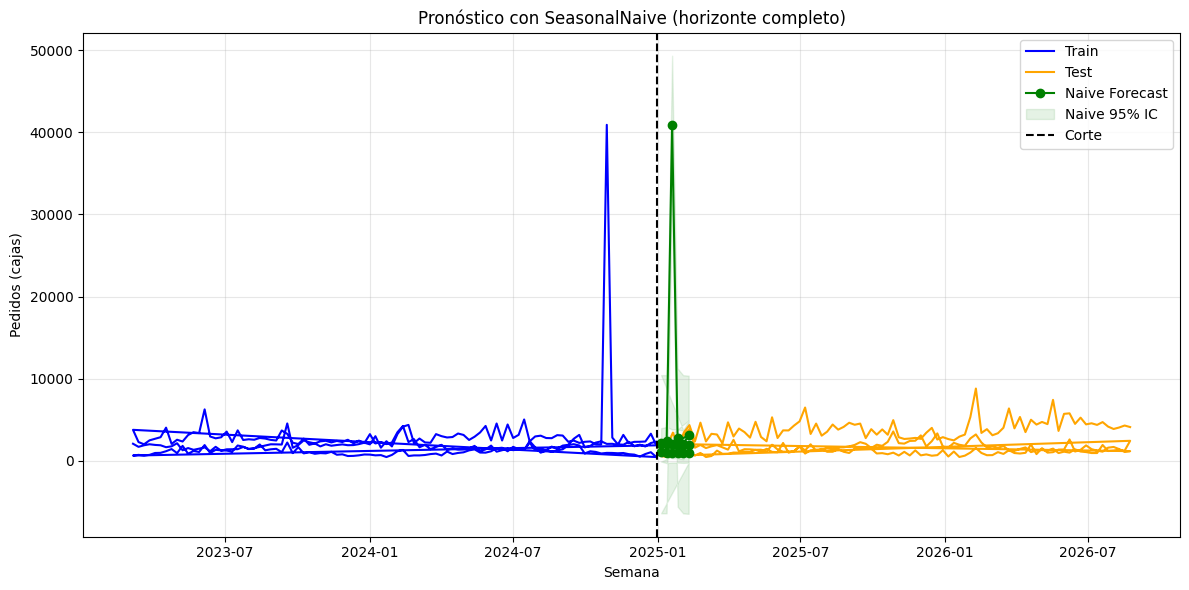

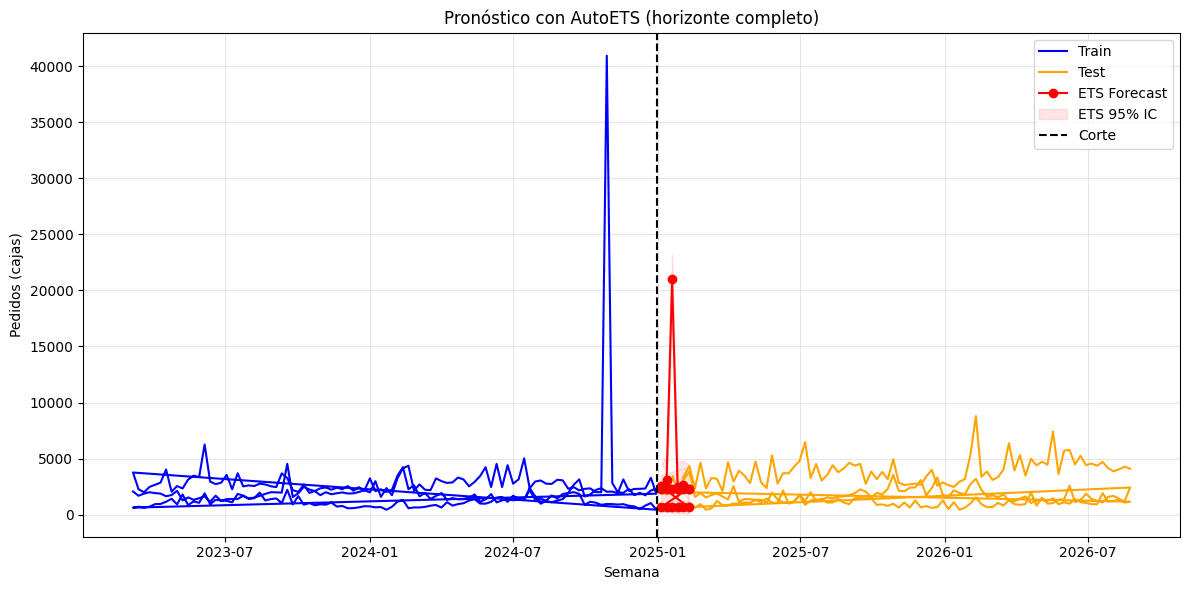

In [28]:
# Gráfico 1: SeasonalNaive a lo largo de todo el horizonte
plt.figure(figsize=(12,6))
plt.plot(df_train['ds'], df_train['y'], label='Train', color='blue')
plt.plot(df_test['ds'], df_test['y'], label='Test', color='orange')
plt.plot(fc['ds'], fc['SeasonalNaive'], label='Naive Forecast', color='green', marker='o')
plt.fill_between(fc['ds'], fc['SeasonalNaive-lo-95'], fc['SeasonalNaive-hi-95'],
                 color='green', alpha=0.1, label='Naive 95% IC')
plt.axvline(corte, color='black', linestyle='--', label='Corte')
plt.title("Pronóstico con SeasonalNaive (horizonte completo)")
plt.xlabel("Semana")
plt.ylabel("Pedidos (cajas)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfico 2: AutoETS a lo largo de todo el horizonte
plt.figure(figsize=(12,6))
plt.plot(df_train['ds'], df_train['y'], label='Train', color='blue')
plt.plot(df_test['ds'], df_test['y'], label='Test', color='orange')
plt.plot(fc['ds'], fc['AutoETS'], label='ETS Forecast', color='red', marker='o')
plt.fill_between(fc['ds'], fc['AutoETS-lo-95'], fc['AutoETS-hi-95'],
                 color='red', alpha=0.1, label='ETS 95% IC')
plt.axvline(corte, color='black', linestyle='--', label='Corte')
plt.title("Pronóstico con AutoETS (horizonte completo)")
plt.xlabel("Semana")
plt.ylabel("Pedidos (cajas)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:
from statsforecast.models import AutoARIMA
sfS=StatsForecast(models=[AutoARIMA(season_length=12)],freq='MS')
sfS.fit(df_train) #busca(p,d,q)(P,D,Q)porAICc
fcS=sfS.predict(h=6,level=[95])
#compararcontraETS y SeasonalNaiveconlaMISMAparticiontemporal




In [26]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive
sf=StatsForecast(
models=[SeasonalNaive(season_length=12), #benchmarkobligatorio
AutoETS(season_length=12)], #ETSelegidoporAICc
freq='W')
sf.fit(df_train)
fc=sf.predict(h=6,level=[80, 95]) #punto+intervalos80/95%

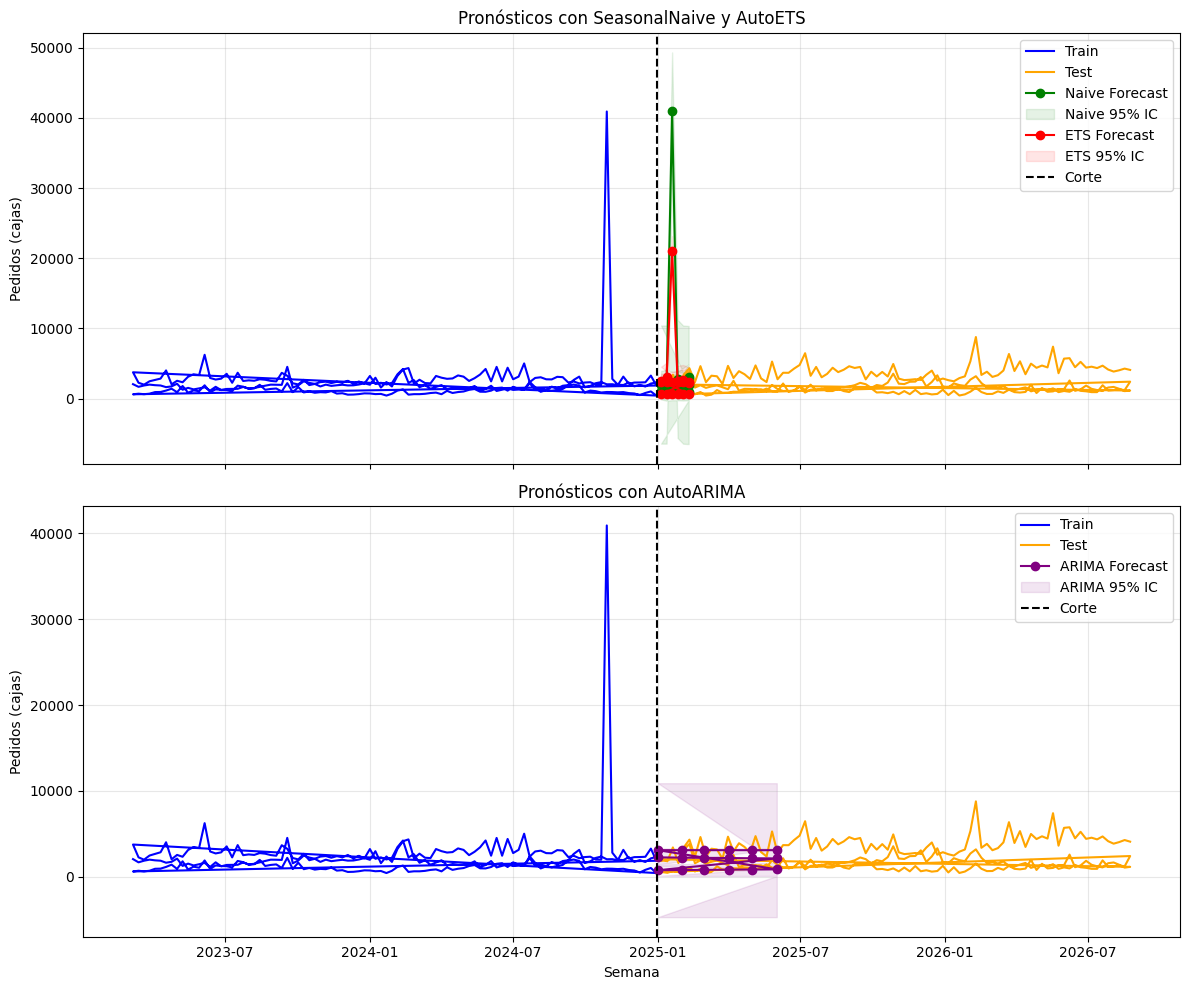

In [27]:
# Ajustar AutoARIMA
from statsforecast.models import AutoARIMA

sfs = StatsForecast(models=[AutoARIMA(season_length=12)], freq='MS')
sfs.fit(df_train)
fcs = sfs.predict(h=6, level=[95])  # ahora fcs está definido

# Gráficos comparativos
fig, axes = plt.subplots(2, 1, figsize=(12,10), sharex=True)

# --- Gráfico superior: sf (ETS + Naive) ---
axes[0].plot(df_train['ds'], df_train['y'], label='Train', color='blue')
axes[0].plot(df_test['ds'], df_test['y'], label='Test', color='orange')

axes[0].plot(fc['ds'], fc['SeasonalNaive'], label='Naive Forecast', color='green', marker='o')
axes[0].fill_between(fc['ds'], fc['SeasonalNaive-lo-95'], fc['SeasonalNaive-hi-95'],
                     color='green', alpha=0.1, label='Naive 95% IC')

axes[0].plot(fc['ds'], fc['AutoETS'], label='ETS Forecast', color='red', marker='o')
axes[0].fill_between(fc['ds'], fc['AutoETS-lo-95'], fc['AutoETS-hi-95'],
                     color='red', alpha=0.1, label='ETS 95% IC')

axes[0].axvline(corte, color='black', linestyle='--', label='Corte')
axes[0].set_title("Pronósticos con SeasonalNaive y AutoETS")
axes[0].set_ylabel("Pedidos (cajas)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Gráfico inferior: sfs (AutoARIMA) ---
axes[1].plot(df_train['ds'], df_train['y'], label='Train', color='blue')
axes[1].plot(df_test['ds'], df_test['y'], label='Test', color='orange')

axes[1].plot(fcs['ds'], fcs['AutoARIMA'], label='ARIMA Forecast', color='purple', marker='o')
axes[1].fill_between(fcs['ds'], fcs['AutoARIMA-lo-95'], fcs['AutoARIMA-hi-95'],
                     color='purple', alpha=0.1, label='ARIMA 95% IC')

axes[1].axvline(corte, color='black', linestyle='--', label='Corte')
axes[1].set_title("Pronósticos con AutoARIMA")
axes[1].set_xlabel("Semana")
axes[1].set_ylabel("Pedidos (cajas)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
